# Mini2P stripe-noise removal utilities

This notebook is designed for large TIFF stacks that may crash the kernel if fully loaded into RAM.

It assumes your raw TIFF is saved as:

```python
frames x height x width
```

For your file, this looked like:

```python
(21820, 512, 512)
```

The interleaved channels are assumed to be:

```python
channel 0 = frames 0, 2, 4, ...
channel 1 = frames 1, 3, 5, ...
```

Change `signal_channel` and `reference_channel` if needed.

## Option 1: Reference-channel stripe subtraction

This uses the structural red channel as a noise reference.

Because the red channel contains real structural fluorescence, this does **not** subtract the whole red image. Instead, it extracts a mostly stripe-shaped component from the reference channel by taking a per-column profile after subtracting each frame's smooth baseline.

This is intended for **vertical stripe noise**. If your stripes are horizontal, set `stripe_axis = "row"`.

In [3]:
import os
import gc
import numpy as np
import tifffile
import matplotlib.pyplot as plt

# ----------------------------
# User settings
# ----------------------------
path = "/Users/megyoung/Desktop/mini2p Images/72Lgoodtask"  # CHANGE THIS
selected_tiff = "72ltask_00001.tif"  # CHANGE THIS if needed

tiff_path = os.path.join(path, selected_tiff)

# Which interleaved channel is GCaMP / functional?
# 0 means raw frames 0, 2, 4, ...
# 1 means raw frames 1, 3, 5, ...
signal_channel = 1

# Which interleaved channel is structural red/reference?
reference_channel = 0

# Processing size. Lower if kernel crashes.
chunk_size = 25

# Output
base = os.path.splitext(selected_tiff)[0]

In [4]:
# ----------------------------
# Inspect TIFF without loading whole thing
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Raw frames:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

n_signal_frames = len(np.arange(signal_channel, n_pages, 2))
n_reference_frames = len(np.arange(reference_channel, n_pages, 2))

print("Signal frames:", n_signal_frames)
print("Reference frames:", n_reference_frames)

Raw frames: 21820
Height: 512
Width: 512
dtype: int16
Signal frames: 10910
Reference frames: 10910


In [5]:
def read_pages_from_open_tif(tif, frame_indices):
    # Read selected TIFF pages into array shaped frames x height x width.
    return np.stack([tif.pages[int(i)].asarray() for i in frame_indices], axis=0)


def robust_rescale_for_display(img, low=1, high=99):
    img = img.astype(np.float32)
    vmin, vmax = np.nanpercentile(img, [low, high])
    return np.clip((img - vmin) / (vmax - vmin + 1e-8), 0, 1)


def preview_interleaved_channel(tiff_path, channel, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(channel, min(n_pages, channel + 2 * n_frames), 2)
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img


def write_chunk(writer, chunk, output_dtype=np.float32):
    # tifffile writes chunk as a multi-page stack.
    # chunk shape: frames x height x width
    writer.write(chunk.astype(output_dtype), photometric="minisblack")

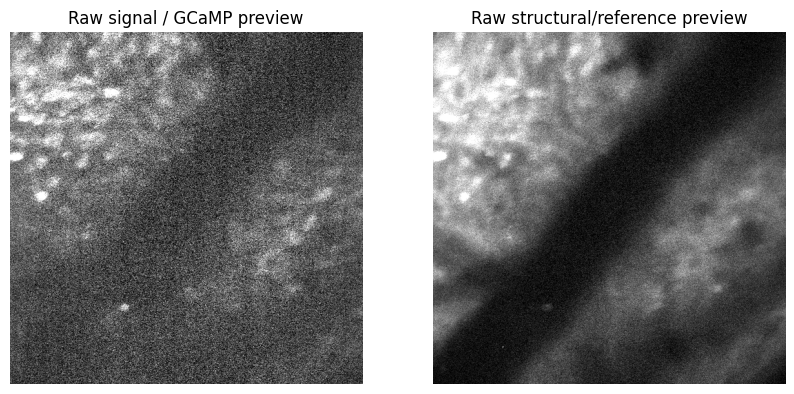

In [6]:
# ----------------------------
# Raw channel previews
# ----------------------------
sig_preview = preview_interleaved_channel(tiff_path, signal_channel, n_frames=200)
ref_preview = preview_interleaved_channel(tiff_path, reference_channel, n_frames=200)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(robust_rescale_for_display(sig_preview), cmap="gray")
plt.title("Raw signal / GCaMP preview")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(robust_rescale_for_display(ref_preview), cmap="gray")
plt.title("Raw structural/reference preview")
plt.axis("off")

plt.show()

In [11]:
# ----------------------------
# Reference-channel stripe subtraction settings
# ----------------------------

# "column" for vertical stripes; "row" for horizontal stripes
stripe_axis = "column"

# Estimate alpha using dim pixels only, to avoid subtracting real cellular structure.
# Smaller value = more conservative. Try 10, 20, 30.
background_percentile = 20

# Smooth the stripe estimate across neighboring columns/rows.
# 1 means no smoothing. Try 3, 5, 9.
smooth_window = 5

# Correction strength multiplier.
# Start at 0.5 or 0.75 if worried about overcorrection.
correction_strength = 0.9

output_file = os.path.join(path, f"{base}_unstriped_reference_subtraction_ch{signal_channel}.tiff")
print("Output:", output_file)

Output: /Users/megyoung/Desktop/mini2p Images/72Lgoodtask/72ltask_00001_unstriped_reference_subtraction_ch1.tiff


In [12]:
def moving_average_1d(x, window=5):
    if window <= 1:
        return x
    kernel = np.ones(window, dtype=np.float32) / window
    return np.convolve(x, kernel, mode="same")


def estimate_stripe_profile(frame, axis="column", smooth_window=5):
    # Estimate stripe profile from one frame.
    # For vertical stripes: returns one value per column.
    # For horizontal stripes: returns one value per row.
    # Uses median across the orthogonal axis so local structures affect it less than mean.
    frame = frame.astype(np.float32)

    if axis == "column":
        profile = np.nanmedian(frame, axis=0)
    elif axis == "row":
        profile = np.nanmedian(frame, axis=1)
    else:
        raise ValueError("axis must be 'column' or 'row'")

    profile = profile - np.nanmedian(profile)

    if smooth_window > 1:
        profile = moving_average_1d(profile, smooth_window)

    return profile.astype(np.float32)


def estimate_alpha_from_background(signal_frame, reference_stripe_frame, percentile=20):
    # Estimate scaling between reference-derived stripe and signal frame
    # using dim pixels in the signal channel.
    signal_frame = signal_frame.astype(np.float32)
    reference_stripe_frame = reference_stripe_frame.astype(np.float32)

    thresh = np.nanpercentile(signal_frame, percentile)
    mask = signal_frame <= thresh

    s = signal_frame[mask]
    r = reference_stripe_frame[mask]

    s = s - np.nanmedian(s)
    r = r - np.nanmedian(r)

    alpha = np.sum(s * r) / (np.sum(r * r) + 1e-8)
    return float(alpha)


def correct_chunk_with_reference(signal_chunk, reference_chunk, axis="column",
                                 background_percentile=20, smooth_window=5,
                                 correction_strength=0.75):
    signal_chunk = signal_chunk.astype(np.float32)
    reference_chunk = reference_chunk.astype(np.float32)

    corrected = np.empty_like(signal_chunk, dtype=np.float32)
    alphas = []

    for i in range(signal_chunk.shape[0]):
        sig = signal_chunk[i]
        ref = reference_chunk[i]

        ref_profile = estimate_stripe_profile(ref, axis=axis, smooth_window=smooth_window)

        if axis == "column":
            ref_stripe_img = np.broadcast_to(ref_profile[None, :], sig.shape).astype(np.float32)
        else:
            ref_stripe_img = np.broadcast_to(ref_profile[:, None], sig.shape).astype(np.float32)

        alpha = estimate_alpha_from_background(sig, ref_stripe_img, percentile=background_percentile)
        alphas.append(alpha)

        corrected[i] = sig - correction_strength * alpha * ref_stripe_img

    return corrected, np.array(alphas)


def run_reference_subtraction(tiff_path, signal_channel, reference_channel, output_file,
                              chunk_size=25, axis="column",
                              background_percentile=20, smooth_window=5,
                              correction_strength=0.75,
                              output_dtype=np.float32):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)

        signal_frames = np.arange(signal_channel, n_pages, 2)
        reference_frames = np.arange(reference_channel, n_pages, 2)

        n = min(len(signal_frames), len(reference_frames))
        signal_frames = signal_frames[:n]
        reference_frames = reference_frames[:n]

        all_alphas = []

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, n, chunk_size):
                end = min(start + chunk_size, n)

                sig_inds = signal_frames[start:end]
                ref_inds = reference_frames[start:end]

                signal_chunk = read_pages_from_open_tif(tif, sig_inds)
                reference_chunk = read_pages_from_open_tif(tif, ref_inds)

                corrected, alphas = correct_chunk_with_reference(
                    signal_chunk,
                    reference_chunk,
                    axis=axis,
                    background_percentile=background_percentile,
                    smooth_window=smooth_window,
                    correction_strength=correction_strength
                )

                write_chunk(writer, corrected, output_dtype=output_dtype)
                all_alphas.extend(alphas.tolist())

                print(f"Saved corrected frames {start} to {end} / {n}; median alpha={np.median(alphas):.4f}")

                del signal_chunk, reference_chunk, corrected, alphas
                gc.collect()

    return np.array(all_alphas)

In [13]:
alphas = run_reference_subtraction(
    tiff_path=tiff_path,
    signal_channel=signal_channel,
    reference_channel=reference_channel,
    output_file=output_file,
    chunk_size=chunk_size,
    axis=stripe_axis,
    background_percentile=background_percentile,
    smooth_window=smooth_window,
    correction_strength=correction_strength,
    output_dtype=np.float32
)

print("Done.")
print("Saved:", output_file)
print("Alpha median:", np.median(alphas))
print("Alpha min/max:", np.min(alphas), np.max(alphas))

Saved corrected frames 0 to 25 / 10910; median alpha=-0.0191
Saved corrected frames 25 to 50 / 10910; median alpha=-0.0200
Saved corrected frames 50 to 75 / 10910; median alpha=-0.0274
Saved corrected frames 75 to 100 / 10910; median alpha=-0.0166
Saved corrected frames 100 to 125 / 10910; median alpha=-0.0174
Saved corrected frames 125 to 150 / 10910; median alpha=-0.0140
Saved corrected frames 150 to 175 / 10910; median alpha=-0.0119
Saved corrected frames 175 to 200 / 10910; median alpha=-0.0128
Saved corrected frames 200 to 225 / 10910; median alpha=-0.0139
Saved corrected frames 225 to 250 / 10910; median alpha=-0.0143
Saved corrected frames 250 to 275 / 10910; median alpha=-0.0140
Saved corrected frames 275 to 300 / 10910; median alpha=-0.0169
Saved corrected frames 300 to 325 / 10910; median alpha=-0.0169
Saved corrected frames 325 to 350 / 10910; median alpha=-0.0179
Saved corrected frames 350 to 375 / 10910; median alpha=-0.0178
Saved corrected frames 375 to 400 / 10910; media

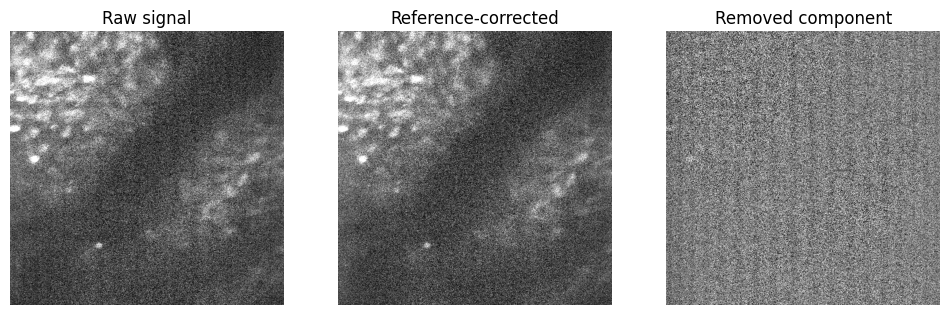

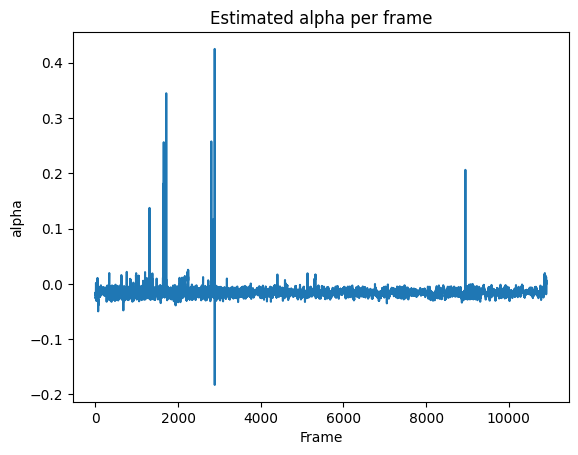

In [14]:
# ----------------------------
# Preview corrected output
# ----------------------------
corrected_preview = preview_interleaved_channel(output_file, channel=0, n_frames=200)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(sig_preview), cmap="gray")
plt.title("Raw signal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(corrected_preview), cmap="gray")
plt.title("Reference-corrected")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(sig_preview - corrected_preview), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

plt.figure()
plt.plot(alphas)
plt.title("Estimated alpha per frame")
plt.xlabel("Frame")
plt.ylabel("alpha")
plt.show()